# 04. Entradas do Modelo 1 (GP Student‑t)

Etapa 4 do fluxo: `01_download.ipynb` → `02_serie_modelos.ipynb` → `03_guia_bases_modelos.ipynb` → `04_entradas_modelo1_gp.ipynb` / `05_entradas_modelo2_rgp.ipynb` / `06_entradas_modelo3_gplvm.ipynb` → notebooks dos modelos (`07`–`09`).

Gera e salva a entrada do GP a partir da `serie` salva no `02_serie_modelos.ipynb`. **Não ajusta o modelo**: isso fica no notebook do modelo, que só lê o arquivo salvo aqui. O que cada variável significa está na seção 4.1 do `03_guia_bases_modelos.ipynb`.

Saída: `data/exports/<NOME>/modelo1_gp/entradas.parquet` (uma linha por estação e dia) e `config.json`. O mesmo arquivo serve para o GP **local** (uma estação por vez) e para o GP **global** (várias estações juntas, com `X = [t, estação]`).

## 1. Carregar os módulos

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root(start: Path) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "src" / "main.py").is_file() and (folder / "data" / "usgs").is_dir():
            return folder
    raise FileNotFoundError("Não encontrei src/main.py e data/usgs. Abra o notebook na pasta do projeto.")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import EXPORT_ROOT
from src.model_data import split_summary
from src.model_exports import gp_table, gp_arrays, gp_global_arrays, save_inputs

## 2. Ler a base

In [2]:
NOME = "serie_2010_2025_200est"   # o mesmo NOME do 02_serie_modelos.ipynb

serie = pd.read_parquet(EXPORT_ROOT / f"{NOME}.parquet")
print("Base:", (EXPORT_ROOT / f"{NOME}_config.json").read_text(encoding="utf-8"))
print(f"{len(serie):,} linhas | {serie['sensor_id'].nunique()} estações")

Base: {
  "selecao": {
    "n_sensors": 200,
    "min_completeness": 0.95,
    "max_zero_frac": 0.05,
    "candidates": null,
    "seed": 42
  },
  "splits": {
    "fracs": [
      0.6,
      0.15,
      0.1,
      0.15
    ],
    "hidden_frac": 0.1,
    "hidden_block_len": 1,
    "log_transform": true,
    "seed": 42
  },
  "periodo": [
    "2010-01-01",
    "2025-12-31"
  ],
  "parametro": "00060",
  "estatistica": "00003"
}
1,168,800 linhas | 200 estações


## 3. Estação do caso local

O GP é ajustado uma estação por vez; a entrada salva tem as 200. A estação do caso local é a usada para avaliar a detecção numa série: precisa ter anomalias rotuladas no teste e é escolhida **antes de rodar o modelo**, pela presença de rótulos e pela cobertura, nunca pelo desempenho. A lista completa de candidatas está na seção 4.4 do `02_serie_modelos.ipynb`.

In [3]:
# Candidatas: pelo menos 20 dias rotulados e 80% de dias visíveis no teste
teste = serie[serie["split"] == "teste"].groupby("sensor_id").agg(
    anom_teste=("anomalia", "sum"), visivel_teste=("visivel", "mean"))
candidatas = teste[(teste["anom_teste"] >= 20) & (teste["visivel_teste"] >= 0.8)].sort_values(
    "anom_teste", ascending=False)
print(f"{len(candidatas)} estações candidatas")
display(candidatas.round(2).head(10))

ESTACAO = "USGS-11224000"   # escolha uma das candidatas
assert ESTACAO in candidatas.index, "A estação escolhida não está entre as candidatas."

13 estações candidatas


,anom_teste,visivel_teste
sensor_id,,
USGS-11224000,125,0.91
USGS-05330000,90,0.91
USGS-10336660,88,0.91
USGS-11370500,72,0.91
USGS-06033000,50,0.86
USGS-10336645,41,0.91
USGS-05317000,40,0.87
USGS-05319500,35,0.86
USGS-05372995,31,0.87


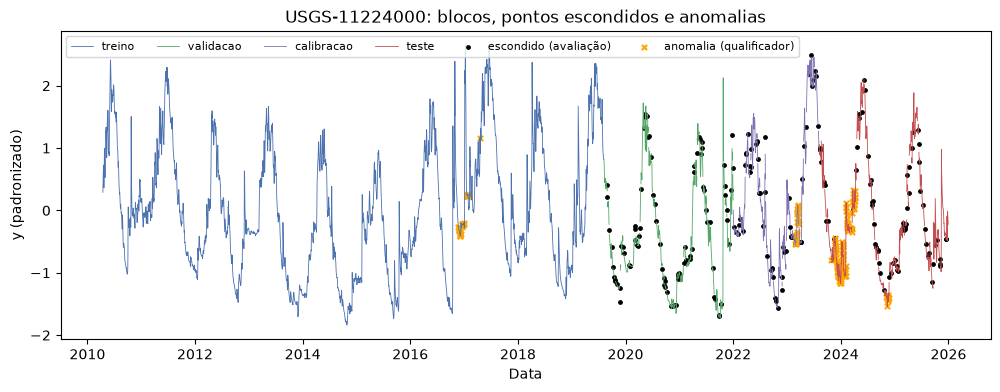

,inicio,fim,linhas,visiveis,escondidos,anomalias,provisorios
split,,,,,,,
treino,2010-01-01,2019-08-07,3506,3401,0,41,0
validacao,2019-08-08,2021-12-31,877,790,87,0,0
calibracao,2022-01-01,2023-08-07,584,528,56,23,0
teste,2023-08-08,2025-12-31,877,802,75,125,0


In [4]:
s = serie[serie["sensor_id"] == ESTACAO]

fig, ax = plt.subplots(figsize=(12, 4))
cores = {"treino": "#4C72B0", "validacao": "#55A868", "calibracao": "#8172B2", "teste": "#C44E52"}
for nome, g in s.groupby("split", sort=False):
    ax.plot(g["data"], g["y"].where(g["visivel"] == 1), lw=0.6, color=cores[nome], label=nome)
h = s[s["escondido_aval"] == 1]
ax.scatter(h["data"], h["y"], s=6, color="black", label="escondido (avaliação)")
a = s[s["anomalia"] == 1]
ax.scatter(a["data"], a["y"], s=14, marker="x", color="orange", label="anomalia (qualificador)")
ax.set(title=f"{ESTACAO}: blocos, pontos escondidos e anomalias", xlabel="Data", ylabel="y (padronizado)")
ax.legend(ncol=6, fontsize=8, loc="upper left")
plt.show()

display(split_summary(s))

## 4. Montar e conferir a entrada

Uma linha por (estação, dia), com `sensor_id`, `t`, `data`, `split`, `y` e três marcadores:

| Coluna | 1 quando o dia… | Uso no GP |
|---|---|---|
| `ajuste` | é visível e está no treino | ajustar o modelo (`X_train`, `Y_train`) |
| `visivel` | tem valor e não foi escondido, em qualquer bloco | contexto das previsões, com hiperparâmetros congelados |
| `escondido_aval` | tem valor, mas foi escondido | onde prever para medir a reconstrução; o `y` desses dias é **só para a métrica** |

Os rótulos de anomalia não vão para este arquivo: ficam na `serie`, que é o que a avaliação lê.

In [5]:
entradas = gp_table(serie)

# Dias por estação e uso (mediana, mínimo e máximo entre as 200 estações)
uso = entradas.groupby("sensor_id").agg(
    ajuste=("ajuste", "sum"), contexto=("visivel", "sum"), escondidos=("escondido_aval", "sum"))
display(uso.describe().loc[["50%", "min", "max"]].round(0))

# Estação local: os vetores que o GP recebe (sem NaN)
gp = gp_arrays(entradas, ESTACAO)
for nome, v in [("t_train", gp["t_train"]), ("y_train", gp["y_train"]), ("t_context", gp["t_context"]),
                ("t_hidden teste", gp["splits"]["teste"]["t_hidden"])]:
    print(f"{nome:15s} {v.shape}  NaN: {np.isnan(v).any()}")

,ajuste,contexto,escondidos
50%,3506.0,5612.0,232.0
min,3340.0,3554.0,5.0
max,3506.0,5626.0,232.0


t_train         (3401,)  NaN: False
y_train         (3401,)  NaN: False
t_context       (5521,)  NaN: False
t_hidden teste  (75,)  NaN: False


**Formato global.** Para um GP com várias estações juntas (por exemplo, kernel `K_tempo × IndexKernel(estação)`), `gp_global_arrays` devolve a mesma estrutura, com `X` de duas colunas: `[t, índice da estação]`. Com as 200 estações são cerca de 700 mil pontos de treino, o que exige um GP variacional esparso (pontos de indução) ou um subconjunto de estações (por exemplo, vizinhas).

In [6]:
gp_global = gp_global_arrays(entradas)   # todas as estações; ou gp_global_arrays(entradas, lista)
for nome, v in [("X_train", gp_global["X_train"]), ("X_context", gp_global["X_context"]),
                ("X_hidden teste", gp_global["splits"]["teste"]["X_hidden"])]:
    print(f"{nome:15s} {v.shape}  NaN: {np.isnan(v).any()}")
print("estações (índice -> ID):", len(gp_global["sensors"]), "| 0 =", gp_global["sensors"][0])

X_train         (700629, 2)  NaN: False
X_context       (1107084, 2)  NaN: False
X_hidden teste  (16305, 2)  NaN: False
estações (índice -> ID): 200 | 0 = USGS-04010500


## 5. Salvar

Se a entrada já existir com as mesmas escolhas, nada é regravado. Se as escolhas mudarem (outra base ou outra estação local), a célula para com erro: apague a pasta `data/exports/<NOME>/modelo1_gp/` para gerar de novo.

In [7]:
save_inputs(entradas, NOME, "modelo1_gp", config={
    "estacoes": sorted(entradas["sensor_id"].unique().tolist()),
    "estacao_local": ESTACAO,
    "criterio_estacao_local": "anomalias no teste >= 20 e dias visíveis no teste >= 80%",
})

Entrada salva em C:\Users\aliss\OneDrive\Repositorios\usgs_streamflow\data\exports\serie_2010_2025_200est\modelo1_gp\entradas.parquet


WindowsPath('C:/Users/aliss/OneDrive/Repositorios/usgs_streamflow/data/exports/serie_2010_2025_200est/modelo1_gp/entradas.parquet')

## 6. Como o notebook do modelo lê esta entrada

```python
from src.model_exports import load_inputs, gp_arrays

entradas, cfg = load_inputs("serie_2010_2025_200est", "modelo1_gp")
gp = gp_arrays(entradas, cfg["estacao_local"])          # ou qualquer estação de cfg["estacoes"]

X_train, Y_train = gp["t_train"], gp["y_train"]         # ajuste
X_ctx, Y_ctx = gp["t_context"], gp["y_context"]         # contexto
X_test, X_test_hid = gp["splits"]["teste"]["t_all"], gp["splits"]["teste"]["t_hidden"]
Y_test_hid = gp["splits"]["teste"]["y_hidden"]          # só para a métrica
```

`gp_arrays` devolve o mesmo dicionário que `gp_inputs` (seção 4.1 do `03_guia_bases_modelos.ipynb`).

**GP global** (várias estações juntas):

```python
from src.model_exports import load_inputs, gp_global_arrays

entradas, cfg = load_inputs("serie_2010_2025_200est", "modelo1_gp")
gp = gp_global_arrays(entradas, cfg["estacoes"])       # ou uma lista menor (ex.: vizinhas)

X_train, Y_train = gp["X_train"], gp["y_train"]         # X: (N, 2) = [t, índice da estação]
X_ctx, Y_ctx = gp["X_context"], gp["y_context"]
X_test_hid = gp["splits"]["teste"]["X_hidden"]
Y_test_hid = gp["splits"]["teste"]["y_hidden"]         # só para a métrica
estacao_de = gp["sensors"]                              # índice -> sensor_id, para devolver a saída
```

No global, `estacao_local` do `config.json` não é usada.